In [1]:
%load_ext cuml.accel
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


[2025-07-04 03:07:53.320] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-07-04 03:08:07.858] [CUML] [info] cuML: Installed accelerator for umap.
[2025-07-04 03:08:07.872] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-07-04 03:08:07.872] [CUML] [info] cuML: Successfully initialized accelerator.


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ealaxi/banksim1")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


In [3]:
data= pd.read_csv(path+"/bs140513_032310.csv")

In [4]:
print("First few rows of the dataset:")
print(data.head())
print("\nData types and non-null counts:")
print(data.info())
print("\nDescriptive statistics:")
print(data.describe())

First few rows of the dataset:
   step       customer  age gender zipcodeOri       merchant zipMerchant  \
0     0  'C1093826151'  '4'    'M'    '28007'   'M348934600'     '28007'   
1     0   'C352968107'  '2'    'M'    '28007'   'M348934600'     '28007'   
2     0  'C2054744914'  '4'    'F'    '28007'  'M1823072687'     '28007'   
3     0  'C1760612790'  '3'    'M'    '28007'   'M348934600'     '28007'   
4     0   'C757503768'  '5'    'M'    '28007'   'M348934600'     '28007'   

              category  amount  fraud  
0  'es_transportation'    4.55      0  
1  'es_transportation'   39.68      0  
2  'es_transportation'   26.89      0  
3  'es_transportation'   17.25      0  
4  'es_transportation'   35.72      0  

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  

In [5]:
# Step 2: Identify numerical features for clustering
numerical_data = data.select_dtypes(include=['int64', 'float64'])
print("\nNumerical features in the dataset:")
print(numerical_data.columns)


Numerical features in the dataset:
Index(['step', 'amount', 'fraud'], dtype='object')


In [6]:

# Step 3: Preprocess the data
# Handle missing values (if any)
numerical_data = numerical_data.fillna(numerical_data.mean())

# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numerical_data)

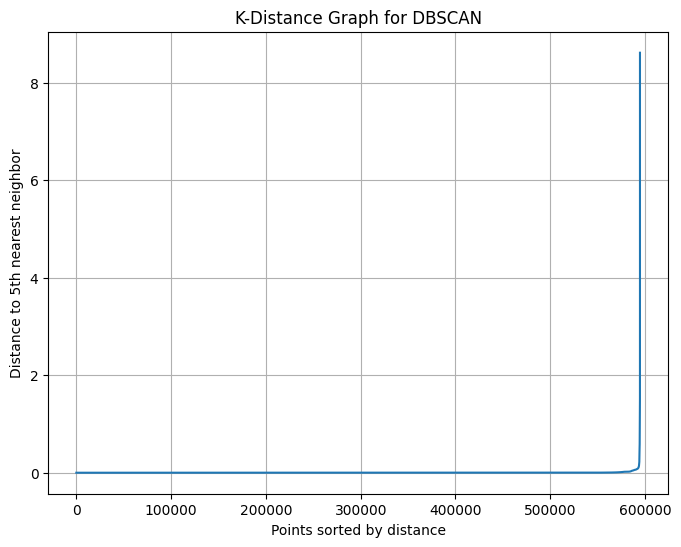

In [7]:
# Step 4: Determine DBSCAN parameters
# Find the optimal eps using the k-distance graph
neigh = NearestNeighbors(n_neighbors=5)  # min_samples is usually set to 2 * dimension
nbrs = neigh.fit(scaled_data)
distances, indices = nbrs.kneighbors(scaled_data)

# Plot the k-distance graph
distances = np.sort(distances[:, -1], axis=0)
plt.figure(figsize=(8, 6))
plt.plot(distances)
plt.xlabel('Points sorted by distance')
plt.ylabel('Distance to 5th nearest neighbor')
plt.title('K-Distance Graph for DBSCAN')
plt.grid()
plt.show()

# From the plot, choose eps (e.g., the "elbow" point)


In [8]:
eps_value = float(input("Enter the eps value based on the k-distance graph (e.g., 0.5): "))
min_samples = 5  # You can adjust this based on your dataset size

Enter the eps value based on the k-distance graph (e.g., 0.5): 20


In [9]:

# Step 5: Apply DBSCAN
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
clusters = dbscan.fit_predict(scaled_data)

# Add cluster labels to the original data
data['cluster'] = clusters



[2025-07-04 03:09:51.655] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 4252 -> 3611. Using the larger integer type might result in better performance



Number of points in each cluster:
0    594643
Name: count, dtype: int64


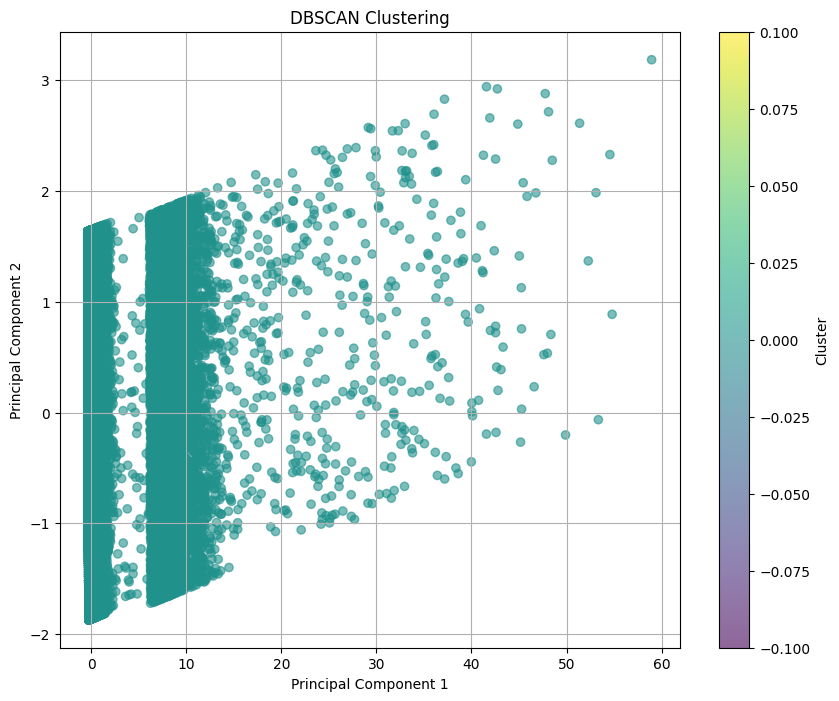

In [10]:
# Step 6: Analyze and visualize the clusters
print("\nNumber of points in each cluster:")
print(pd.Series(clusters).value_counts())

# Visualize clusters using PCA for dimensionality reduction
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_data)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(principal_components[:, 0], principal_components[:, 1], c=clusters, cmap='viridis', alpha=0.6)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clustering')
plt.colorbar(scatter, label='Cluster')
plt.grid()
plt.show()



In [11]:
# Step 7: Save the results if needed
data.to_csv('banksim_with_clusters.csv', index=False)
print("\nClustered data saved to 'banksim_with_clusters.csv'")



Clustered data saved to 'banksim_with_clusters.csv'
